In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from farmrl import data_loader as dl
from farmrl.yield_model import YieldModel, PRIORS
from farmrl.env import FarmEnv, OBS_NAMES
from farmrl.baselines import BASELINES, recommended_schedule
from farmrl.evaluation import evaluate, summarise, run_episode
from farmrl.agents.ppo import PPO
from farmrl.utils import load_config, set_seed, save_fig, set_plot_style, COLORS, POLICY_COLORS

cfg = load_config(ROOT / "configs/default.yaml")
SEED = cfg["env"]["seed"]
set_seed(SEED)
set_plot_style()
pd.set_option("display.precision", 2)
MUTED = "#898781"

def show(fig, name):
    path = save_fig(fig, name)
    plt.show()
    print("saved", path.relative_to(ROOT))

In [2]:
REGION = cfg["env"]["region"]
daily = dl.load_weather(cfg["env"]["weather_site"])
seasons = dl.load_seasons(cfg["env"]["weather_site"], steps=cfg["env"]["steps_per_season"])
summary = dl.season_summary(seasons)
train_years, test_years = dl.split_seasons(seasons, cfg["env"]["train_end"])
icrisat = dl.load_icrisat("wheat", min_area_kha=cfg["yield_fit"]["min_area_kha"])
fit_table = dl.build_fit_table("wheat", min_area_kha=cfg["yield_fit"]["min_area_kha"])
prices = dl.load_prices(region=REGION)
costs = dl.load_cost_of_cultivation(state=REGION.title())

def optional(loader):
    try:
        return loader()
    except FileNotFoundError as err:
        print("MISSING:", err)

fao = optional(dl.load_fao_pesticides)
mandi = optional(dl.load_agmarknet)

print(f"weather   : {len(daily)} days, {daily['date'].min():%Y-%m-%d} to {daily['date'].max():%Y-%m-%d}; "
      f"{summary['season'].nunique()} complete seasons")
print(f"ICRISAT   : {len(icrisat)} district-years with > {cfg['yield_fit']['min_area_kha']:.0f} thousand ha of wheat, "
      f"{icrisat['state'].nunique()} states, {icrisat['district'].nunique()} districts, {icrisat['year'].min()}-{icrisat['year'].max()}")
print(f"fit table : {len(fit_table)} district-years with weather; "
      f"{fit_table.dropna(subset=['n_kg_ha', 'irrigated_share']).shape[0]} with nitrogen and irrigated share")
print(f"prices    : {len(prices)} seasons {prices['season'].min()}-{prices['season'].max()}, "
      f"sources {sorted(prices['source'].unique())}")
print(f"costs     : CACP years {sorted(costs['year'].unique())}")
print(f"FAO       : {'%d years' % len(fao) if fao is not None else 'not available'}")
print(f"Agmarknet : {'%d months' % len(mandi) if mandi is not None else 'not available'}")

MISSING: D:\MyStuff\College\.7thSemester\AI\Ass2\FarmRL\data\raw\agmarknet_wheat_punjab.csv not found -- see scripts/download_data.py prices
weather   : 14610 days, 1985-01-01 to 2024-12-31; 39 complete seasons
ICRISAT   : 2071 district-years with > 10 thousand ha of wheat, 15 states, 220 districts, 2008-2017
fit table : 2071 district-years with weather; 1724 with nitrogen and irrigated share
prices    : 45 seasons 1981-2025, sources ['ICRISAT farm harvest price (Punjab districts)', 'MSP (RBI Handbook)']
costs     : CACP years ['2022-23', '2023-24', '2024-25']
FAO       : 24 years
Agmarknet : not available


24 years (1990-2013); 22 repeated rows per year collapsed; 1 year restored from the source files; measure: index (national tonnage / series mean)


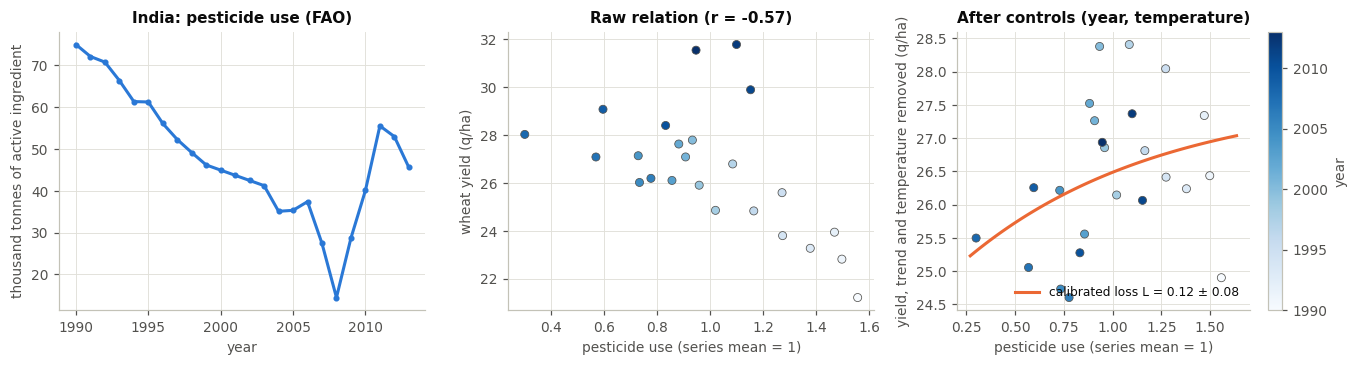

saved results\figures\eda_pesticide_vs_yield.png


In [3]:
if fao is None:
    print("yield_df.csv is not in data/raw, so there is no pesticide data to plot.")
    print("Save it there (or add ~/.kaggle/kaggle.json and run `python scripts/download_data.py kaggle`), then re-run.")
else:
    print(f"{len(fao)} years ({fao['year'].min()}-{fao['year'].max()}); {int(fao['n_temp_rows'].max())} repeated rows per year collapsed; "
          f"{(fao['source'] != 'yield_df.csv').sum()} year restored from the source files; measure: {fao['normalisation'].iloc[0]}")
    cal = YieldModel().calibrate_pesticide(fao)
    fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
    axes[0].plot(fao["year"], fao["pesticides_t"] / 1000, color=COLORS[0], marker="o", ms=3, label="pesticide use (kt)")
    axes[0].set(xlabel="year", ylabel="thousand tonnes of active ingredient", title="India: pesticide use (FAO)")
    sc = axes[1].scatter(cal["x"], cal["observed"], c=cal["year"], cmap="Blues", s=28, edgecolor="#52514e", lw=0.5)
    r = np.corrcoef(cal["x"], cal["observed"])[0, 1]
    axes[1].set(xlabel="pesticide use (series mean = 1)", ylabel="wheat yield (q/ha)", title=f"Raw relation (r = {r:+.2f})")
    axes[2].scatter(cal["x"], cal["partial_yield"], c=cal["year"], cmap="Blues", s=28, edgecolor="#52514e", lw=0.5)
    grid = np.linspace(cal["x"].min() * 0.9, cal["x"].max() * 1.05, 100)
    level = (cal["partial_yield"] / (1 - cal["estimate"] * np.exp(-cal["k_fixed"] * cal["x"]))).mean()
    axes[2].plot(grid, level * (1 - cal["estimate"] * np.exp(-cal["k_fixed"] * grid)), color=COLORS[1],
                 label=f"calibrated loss L = {cal['estimate']:.2f} ± {cal['std_err']:.2f}")
    axes[2].set(xlabel="pesticide use (series mean = 1)", ylabel="yield, trend and temperature removed (q/ha)",
                title=f"After controls ({', '.join(cal['controls'])})")
    axes[2].legend(loc="lower right")
    fig.colorbar(sc, ax=axes[2], label="year")
    fig.tight_layout()
    show(fig, "eda_pesticide_vs_yield")

In [4]:
from farmrl import fitting
model, rep = fitting.fit_yield_model(cfg, fit_table, pest_df=fao)
print("\n".join(fitting.describe(model, rep)))

h = rep["holdout"]
scores = pd.DataFrame({"R²": [rep["r2"], h["r2_train"], h["r2_test"], h["r2_test_state_means_only"]],
                       "rows": [rep["n_obs"], h["n_train"], h["n_test"], h["n_test"]]},
                      index=["pooled fit, all years (in-sample)", f"pooled fit, years < {h['from_year']} (in-sample)",
                             f"pooled fit, held-out years >= {h['from_year']}", "state means only, held-out years"])
display(scores.round(3))
if rep["comparison"]:
    display(pd.DataFrame(rep["comparison"]).T[["n_test", "single_region_r2_test", "pooled_r2_test",
                                               "single_region_rmse_test", "pooled_rmse_test"]].round(3))
display(pd.Series(rep["state_effects"], name="plateau yield A_state (q/ha)").sort_values(ascending=False).round(1).to_frame())

yield model: pooled panel, 1719 district-years, 13 states (state fixed effects)
  in-sample R2 = 0.686, RMSE = 6.02 q/ha
  held-out years >= 2015: R2 = 0.512, RMSE = 7.28 q/ha (n = 471, fitted on 1248)
      state means alone give R2 = 0.400; within states the model explains +18.7% of the remaining variance
  Haryana rows only, held-out years (n = 21): single-region N+rain fit R2 = -0.257 (RMSE 3.51); pooled fit R2 = -1.026 (RMSE 4.46)
  Punjab rows only, held-out years (n = 33): single-region N+rain fit R2 = -0.549 (RMSE 4.31); pooled fit R2 = -1.056 (RMSE 4.96)
  y_max         49.8203  (fitted)
  n_coef         0.0208  (fitted)
  w_opt        400.0000  (not identified -> neutral/prior)
  w_excess       0.0000  (not identified -> neutral/prior)
  pest_loss      0.1151  (calibrated, n = 24 national years; was 0.35)
  soil_n        30.0000
  ky             0.7065  (calibrated to the fitted rainfed loss)
  y_scale        1.0690
  heat_coef      0.0023  (fitted)
  k_dry          0.3923  (

,R²,rows
"pooled fit, all years (in-sample)",0.69,1719
"pooled fit, years < 2015 (in-sample)",0.71,1248
"pooled fit, held-out years >= 2015",0.51,471
"state means only, held-out years",0.40,471


,n_test,single_region_r2_test,pooled_r2_test,single_region_rmse_test,pooled_rmse_test
Haryana,21.0,-0.26,-1.03,3.51,4.46
Punjab,33.0,-0.55,-1.06,4.31,4.96


,plateau yield A_state (q/ha)
Punjab,49.8
Haryana,49.2
Rajasthan,42.9
Madhya Pradesh,38.7
Uttarakhand,36.3
Gujarat,35.5
Uttar Pradesh,34.8
Bihar,29.1
Himachal Pradesh,27.7
Maharashtra,20.0


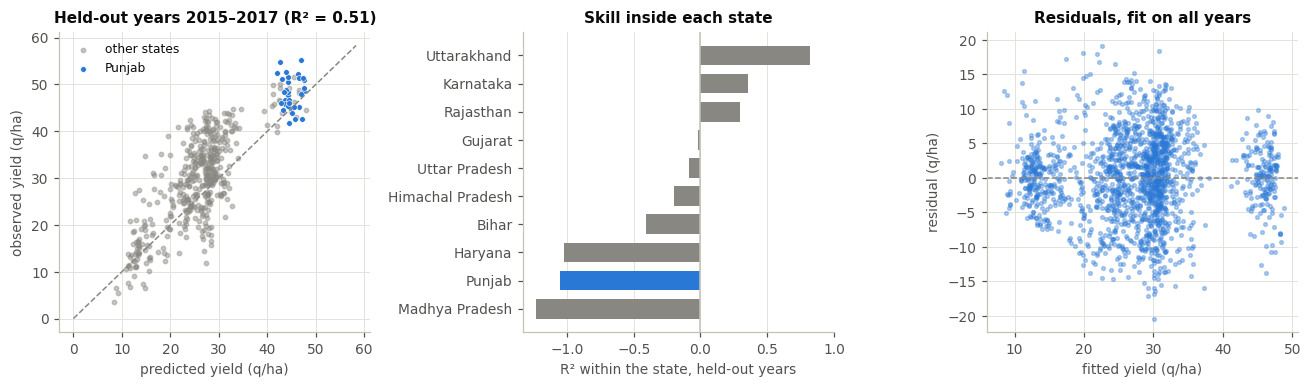

saved results\figures\yield_fit_diagnostics.png


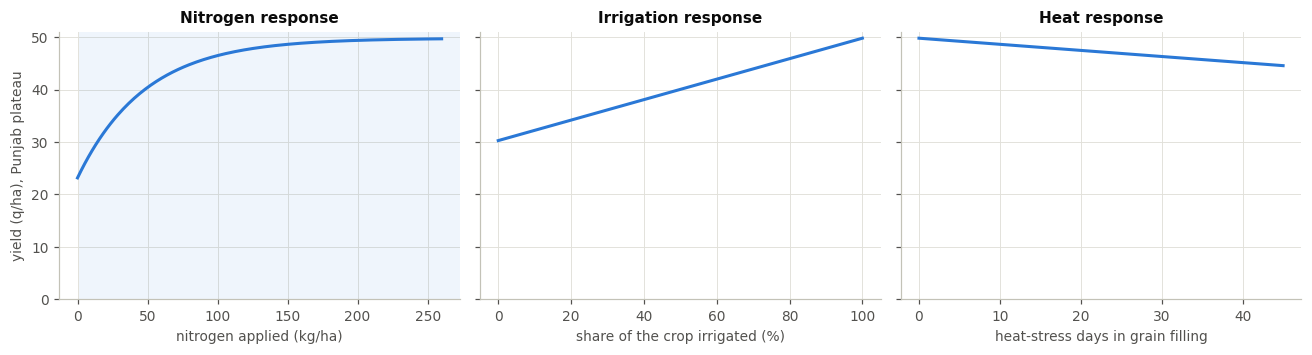

saved results\figures\yield_response_curves.png


In [5]:
held = rep["holdout_rows"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
ax = axes[0]
is_region = held["state"].str.lower() == REGION.lower()
ax.scatter(held.loc[~is_region, "predicted"], held.loc[~is_region, "yield_q_ha"], s=8, color="#898781", alpha=0.45, label="other states")
ax.scatter(held.loc[is_region, "predicted"], held.loc[is_region, "yield_q_ha"], s=14, color=COLORS[0], edgecolor="white", lw=0.4, label=REGION.title())
lim = [0, max(held["predicted"].max(), held["yield_q_ha"].max()) + 3]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
ax.set(xlabel="predicted yield (q/ha)", ylabel="observed yield (q/ha)", title=f"Held-out years {h['from_year']}–{held['year'].max()} (R² = {h['r2_test']:.2f})")
ax.legend(loc="upper left")

ax = axes[1]
by_state = pd.Series(h["by_state"]).sort_values()
ax.barh(by_state.index, by_state.values, color=[COLORS[0] if s.lower() == REGION.lower() else "#898781" for s in by_state.index], height=0.7)
ax.axvline(0, color="#c3c2b7", lw=1)
ax.set(xlabel="R² within the state, held-out years", title="Skill inside each state")
ax.set_xlim(max(-2.5, by_state.min() - 0.1), 1)
ax.grid(axis="y", visible=False)

ax = axes[2]
res = rep["data"].assign(residual=lambda d: d["yield_q_ha"] - d["predicted"])
ax.scatter(res["predicted"], res["residual"], s=6, color=COLORS[0], alpha=0.35)
ax.axhline(0, color=MUTED, lw=1, ls="--")
ax.set(xlabel="fitted yield (q/ha)", ylabel="residual (q/ha)", title="Residuals, fit on all years")
fig.tight_layout()
show(fig, "yield_fit_diagnostics")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
n_grid = np.linspace(0, 260, 200)
axes[0].plot(n_grid, model.y_max * model.n_term(n_grid), color=COLORS[0])
axes[0].axvspan(*rep["n_range_kg_ha"], color=COLORS[0], alpha=0.07, lw=0)
axes[0].set(xlabel="nitrogen applied (kg/ha)", ylabel=f"yield (q/ha), {REGION.title()} plateau", title="Nitrogen response", ylim=(0, None))
share = np.linspace(0, 1, 100)
axes[1].plot(share * 100, model.y_max * (1 - model.k_dry * (1 - share)), color=COLORS[0])
axes[1].set(xlabel="share of the crop irrigated (%)", title="Irrigation response")
days = np.linspace(0, 45, 100)
axes[2].plot(days, model.y_max * model.heat_term(days), color=COLORS[0])
axes[2].set(xlabel="heat-stress days in grain filling", title="Heat response")
fig.tight_layout()
show(fig, "yield_response_curves")

In [6]:
params_path = ROOT / cfg["env"]["fitted_params"]
model.save(params_path, source=f"ICRISAT district-level data ({fit_table['state'].nunique()} states, {fit_table['year'].min()}-"
                               f"{fit_table['year'].max()}) + NASA POWER district weather; region {REGION}")
print(f"ky = {model.ky:.3f}, y_scale = {model.y_scale:.3f}  ->  potential yield {model.y_max * model.y_scale:.1f} q/ha")
print("saved", params_path.relative_to(ROOT))
print(params_path.read_text().split("fit:")[0])

ky = 0.707, y_scale = 1.069  ->  potential yield 53.3 q/ha
saved configs\fitted_params.yaml
params:
  y_max: 49.82029383518054
  n_coef: 0.020839550299222492
  w_opt: 400.0
  w_excess: 0.0
  pest_loss: 0.11508672626908367
  soil_n: 30.0
  ky: 0.7065201360875861
  y_scale: 1.0690140464862448
  heat_coef: 0.00233718454254169
  k_dry: 0.39229838131505834
  r0: 1000000.0
source: ICRISAT district-level data (15 states, 2008-2017) + NASA POWER district weather;
  region punjab

